<a href="https://colab.research.google.com/github/srangisetti27/meridian/blob/main/hr_attrition_assignment_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IBM HR Attrition: Clean, Explore & Engineer

Dataset: [IBM HR Analytics Employee Attrition (Kaggle)](https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset). `Attrition` = Yes means the employee left.

* **(a)** Find and handle missing values, duplicates and outliers
* **(b)** EDA with visualizations: distributions, correlations, group comparisons
* **(c)** Create 2 new features
* **5 key insights** at the end

## Load the dataset

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/WA_Fn-UseC_-HR-Employee-Attrition 2.csv')
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [ ]:
df.shape

(1470, 35)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [6]:
df.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


## (a) Missing values, duplicates and outliers

### Missing values

In [7]:
df.isnull().sum()

,0
Age,0
Attrition,0
BusinessTravel,0
DailyRate,0
Department,0
DistanceFromHome,0
Education,0
EducationField,0
EmployeeCount,0
EmployeeNumber,0


Every column shows 0, so there are **no missing values** to handle.

If there were, we would fill them with the **median**, because outliers affect the mean but not the median:
```python
df['MonthlyIncome'] = df['MonthlyIncome'].fillna(df['MonthlyIncome'].median())
```

### Duplicates

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df = df.drop_duplicates()
df.shape

(1470, 35)

There are 0 duplicate rows, so the shape stays at 1,470 rows.

### Outliers

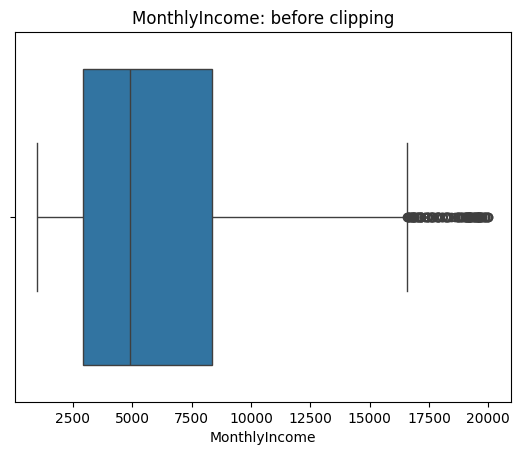

In [10]:
sns.boxplot(x=df['MonthlyIncome'])
plt.title('MonthlyIncome: before clipping')
plt.show()

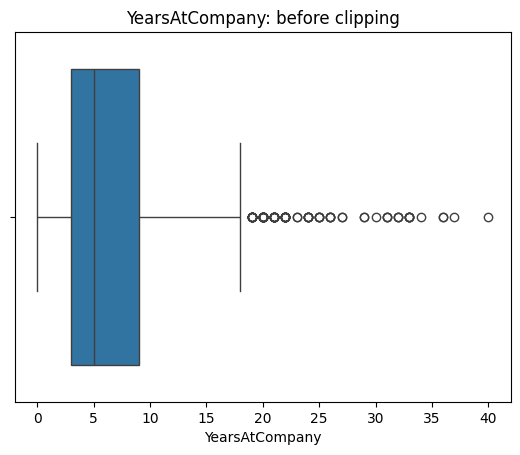

In [11]:
sns.boxplot(x=df['YearsAtCompany'])
plt.title('YearsAtCompany: before clipping')
plt.show()

The dots on the right are outliers. We handle them with **clip**: values above the upper limit are set to the upper limit. The limits are the same ones the boxplot whiskers use (1.5 × IQR). No rows are deleted.

In [12]:
for col in ['MonthlyIncome', 'TotalWorkingYears', 'YearsAtCompany', 'YearsSinceLastPromotion']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    df[col] = df[col].clip(lower, upper)

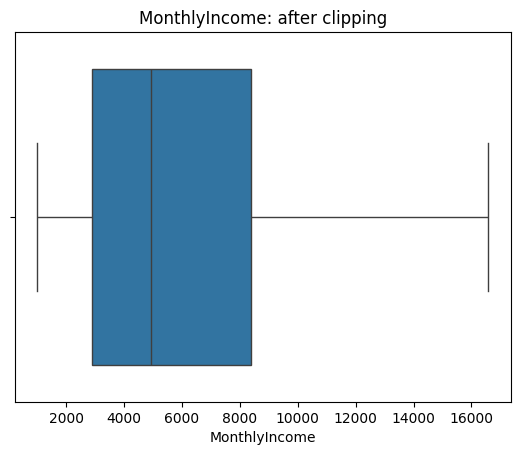

In [13]:
sns.boxplot(x=df['MonthlyIncome'])
plt.title('MonthlyIncome: after clipping')
plt.show()

## (b) EDA

### Distributions (univariate)

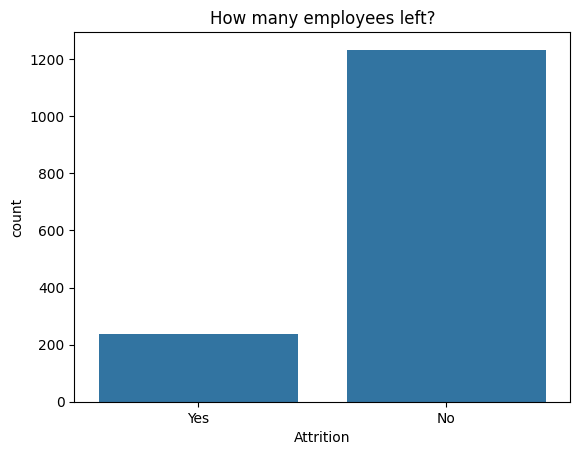

,count
Attrition,
No,1233
Yes,237


In [14]:
sns.countplot(x='Attrition', data=df)
plt.title('How many employees left?')
plt.show()

df['Attrition'].value_counts()

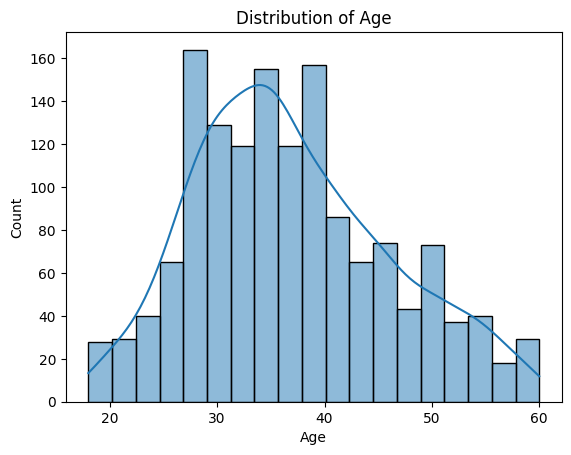

In [15]:
sns.histplot(df['Age'], kde=True)
plt.title('Distribution of Age')
plt.show()

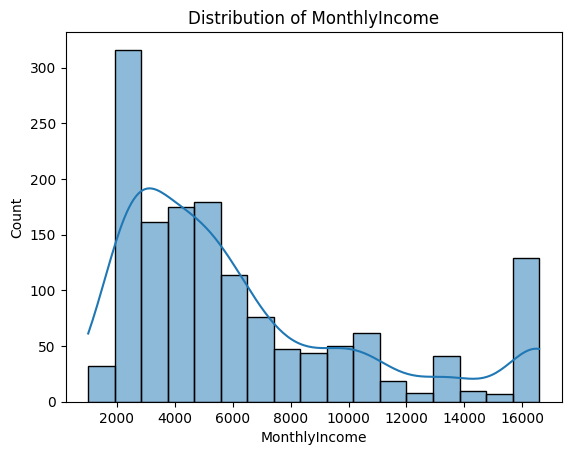

In [16]:
sns.histplot(df['MonthlyIncome'], kde=True)
plt.title('Distribution of MonthlyIncome')
plt.show()

In [ ]:
df[['Age', 'MonthlyIncome']].skew()

Age              0.413286
MonthlyIncome    1.168595
dtype: float64

* **Age** has skew of about 0.4, so it is close to a **normal distribution**.
* **MonthlyIncome** has skew of about 1.2, so it is **right skewed**: most people earn less, with a long tail of high earners. It's still right skewed after clipping, because clipping only caps the most extreme values.
* The tall bar at the far right of the income histogram (about 16,500) is the clipped values. Every income above the upper limit was set to that limit, so they all pile up there.

### Group comparisons (bivariate)

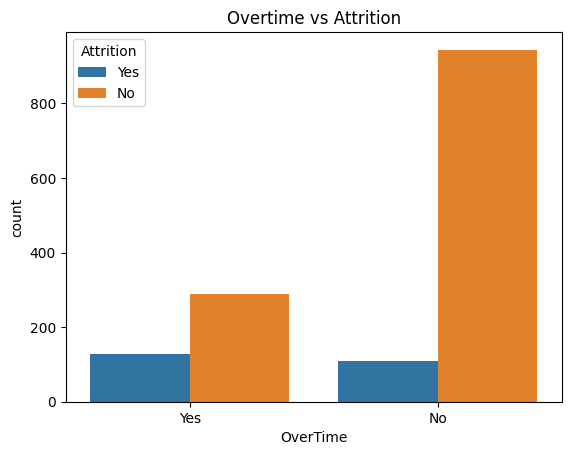

In [17]:
sns.countplot(x='OverTime', hue='Attrition', data=df)
plt.title('Overtime vs Attrition')
plt.show()

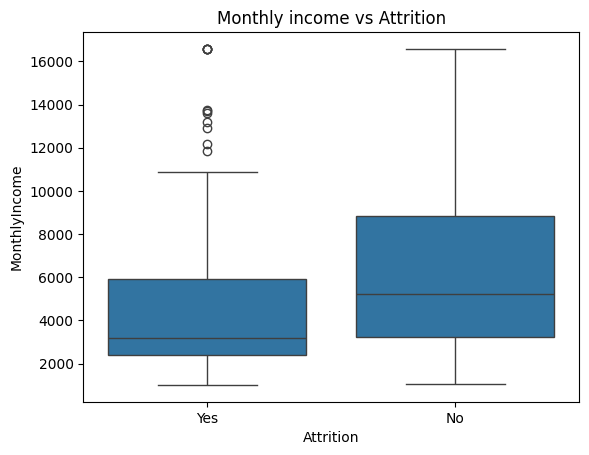

In [18]:
sns.boxplot(x='Attrition', y='MonthlyIncome', data=df)
plt.title('Monthly income vs Attrition')
plt.show()

### Correlations (multivariate)

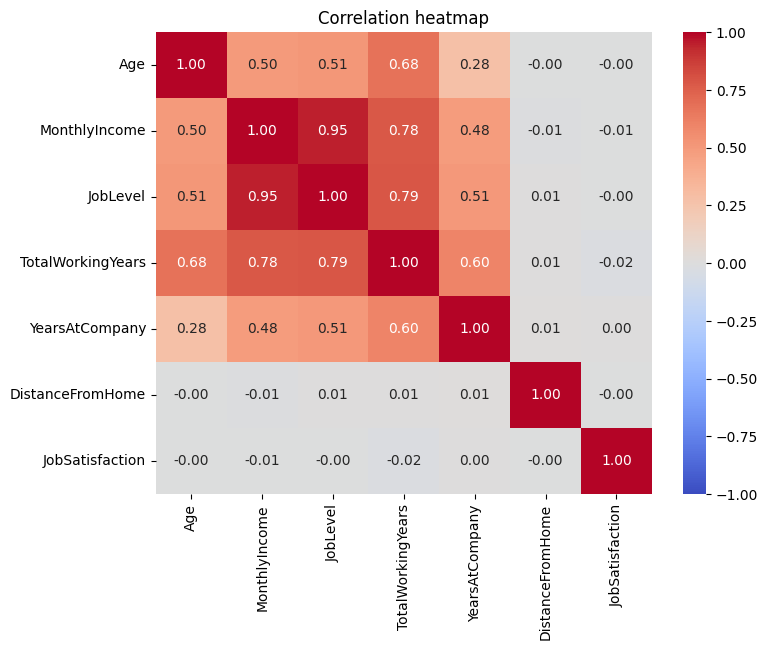

In [19]:
cols = ['Age', 'MonthlyIncome', 'JobLevel', 'TotalWorkingYears',
        'YearsAtCompany', 'DistanceFromHome', 'JobSatisfaction']

plt.figure(figsize=(8, 6))
sns.heatmap(df[cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation heatmap')
plt.show()

## (c) Feature engineering: 2 new features

1. **`TotalSatisfaction`**: the four satisfaction-type ratings added together (each is 1–4, so the total is 4–16). One overall score is easier for a model to use than four small ones.
2. **`YearsPerCompany`**: total working years ÷ number of companies worked at. A low value means the person changes jobs often. I add 1 to the bottom so we never divide by 0.

In [20]:
df['TotalSatisfaction'] = (df['EnvironmentSatisfaction'] + df['JobSatisfaction']
                           + df['RelationshipSatisfaction'] + df['WorkLifeBalance'])

df['YearsPerCompany'] = df['TotalWorkingYears'] / (df['NumCompaniesWorked'] + 1)

df[['TotalSatisfaction', 'YearsPerCompany']].head()

,TotalSatisfaction,YearsPerCompany
0,8,0.888889
1,12,5.000000
2,12,1.000000
3,13,4.000000
4,10,0.600000


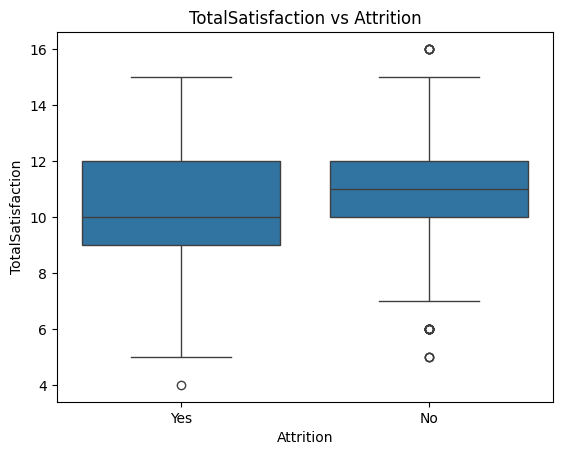

In [21]:
sns.boxplot(x='Attrition', y='TotalSatisfaction', data=df)
plt.title('TotalSatisfaction vs Attrition')
plt.show()

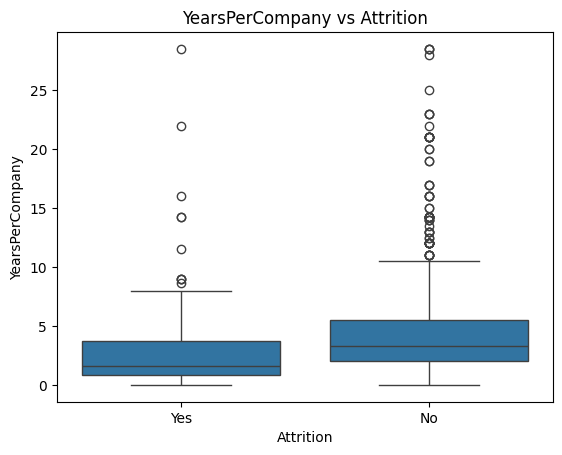

In [22]:
sns.boxplot(x='Attrition', y='YearsPerCompany', data=df)
plt.title('YearsPerCompany vs Attrition')
plt.show()

## 5 Key insights

1. **Most employees stayed.** Only 237 of 1,470 left (about 16%), so the data is imbalanced: there are far more "No" than "Yes".
2. **Overtime is linked to leaving.** About 31% of overtime workers left (127 of 416), compared with about 10% of others (110 of 1,054). That's roughly 3 times higher.
3. **Employees who left earned less.** In the boxplot, the median monthly income of leavers is about 3,200, vs about 5,200 for those who stayed.
4. **Income, job level and experience move together.** In the heatmap, `MonthlyIncome` and `JobLevel` have a correlation of 0.95, and `TotalWorkingYears` is also strongly correlated with both (about 0.78). `DistanceFromHome` and `JobSatisfaction` are almost unrelated to the others (close to 0).
5. **Both new features show a difference.** Leavers have a lower median `TotalSatisfaction` (10 vs 11) and about half the `YearsPerCompany` (about 1.6 vs 3.3 years). People who are less satisfied, or who change jobs often, are more likely to leave, so both features could help a future model.